# Exploratory reliability analysis

This notebook produces descriptive findings from NASA C-MAPSS FD001/FD002 training trajectories when the processed Parquet files are available. It also analyzes the seeded synthetic fleet. Synthetic outputs are simulations, not industrial telemetry. If NASA files are absent (for example, in CI), the notebook uses synthetic data for trajectory and sensor analyses and explicitly identifies that substitution.

Run all cells from the repository root after installing `.[dev]`. Findings are computed from the loaded data; this notebook does not fit predictive models or use future RUL as a sensor input.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from reliability_platform.data.simulator import (
    SyntheticFleetConfig,
    generate_synthetic_fleet,
)
from reliability_platform.data.storage import read_parquet
from reliability_platform.evaluation.reliability import (
    calculate_downtime,
    calculate_failure_rates,
    calculate_maintenance_frequency,
    calculate_mtbf,
    machine_lifetimes,
    summarize_lifetimes,
)

PROJECT_ROOT = next(
    parent
    for parent in (Path.cwd(), *Path.cwd().parents)
    if (parent / "pyproject.toml").exists()
)
PROCESSED = PROJECT_ROOT / "data" / "processed"
synthetic = generate_synthetic_fleet(SyntheticFleetConfig(random_seed=42))
fd001_path = PROCESSED / "cmapss_FD001_train.parquet"
fd002_path = PROCESSED / "cmapss_FD002_train.parquet"
fd001 = read_parquet(fd001_path) if fd001_path.exists() else None
fd002 = read_parquet(fd002_path) if fd002_path.exists() else None
analysis_frame = fd001 if fd001 is not None else synthetic
analysis_label = (
    "NASA C-MAPSS FD001 training"
    if fd001 is not None
    else "synthetic simulation (NASA data not found)"
)
display(Markdown(f"**Trajectory and sensor analysis source:** {analysis_label}."))
display(
    pd.DataFrame(
        [
            {
                "dataset": "NASA C-MAPSS FD001 train",
                "rows": len(fd001),
                "machines": fd001.machine_id.nunique(),
            }
            if fd001 is not None
            else {
                "dataset": "NASA C-MAPSS FD001 train",
                "rows": None,
                "machines": None,
            },
            {
                "dataset": "synthetic simulation",
                "rows": len(synthetic),
                "machines": synthetic.machine_id.nunique(),
            },
        ]
    )
)

**Trajectory and sensor analysis source:** NASA C-MAPSS FD001 training.

,dataset,rows,machines
0,NASA C-MAPSS FD001 train,20631,100
1,synthetic simulation,11935,100


## 1. Observed machine lifetimes

Only machines with an observed terminal failure are treated as completed lifetimes. C-MAPSS test trajectories are excluded because their failure events are not observed.

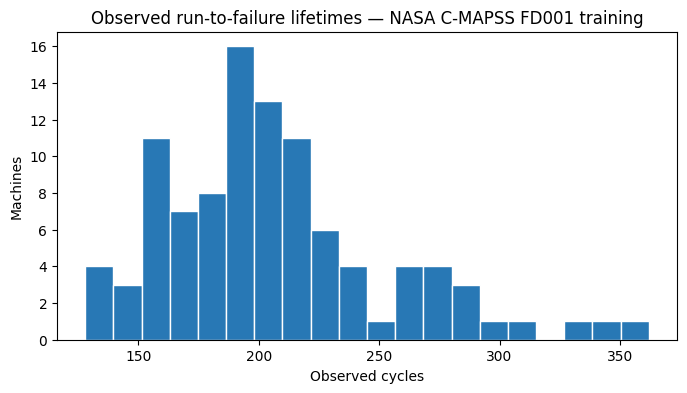

**Finding 1.** 100 machines have observed terminal failures; their median observed lifetime is **199.0 cycles** (IQR 177.0–229.2). The histogram shows the measured distribution.

,source,dataset_split,machine_count,mean_cycles,median_cycles,minimum_cycles,maximum_cycles,failures,censored_machines
0,nasa_cmapss,train,100,206.31,199.0,128,362,100,0


In [2]:
lifetime_table = machine_lifetimes(analysis_frame)
completed_lifetimes = lifetime_table.loc[
    lifetime_table.failure_observed, "exposure_cycles"
]
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(completed_lifetimes, bins=20, color="#2878B5", edgecolor="white")
ax.set(
    title=f"Observed run-to-failure lifetimes — {analysis_label}",
    xlabel="Observed cycles",
    ylabel="Machines",
)
plt.show()
lifetime_median = float(completed_lifetimes.median())
lifetime_q1, lifetime_q3 = completed_lifetimes.quantile([0.25, 0.75])
display(
    Markdown(
        f"**Finding 1.** {len(completed_lifetimes)} machines have observed terminal "
        f"failures; their median observed lifetime is **{lifetime_median:.1f} "
        f"cycles** (IQR {lifetime_q1:.1f}–{lifetime_q3:.1f}). The histogram shows "
        "the measured distribution."
    )
)
summarize_lifetimes(analysis_frame)

## 2. RUL labels along observed trajectories

RUL is a target label. This plot checks its construction in completed trajectories; it is not used as a sensor input or as evidence that a sensor predicts failure.

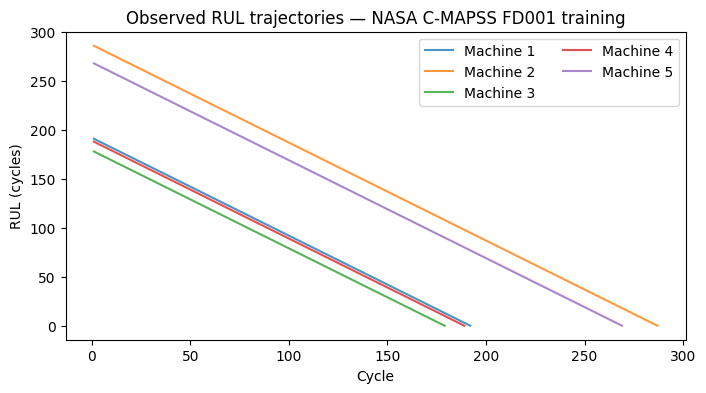

**Finding 2.** For the 5 displayed completed trajectories, the mean fitted RUL-vs-cycle slope is **-1.000 cycles/cycle**. This is a label-consistency check, not a model result.

In [3]:
example_ids = analysis_frame.machine_id.drop_duplicates().head(5).tolist()
fig, ax = plt.subplots(figsize=(8, 4))
rul_slopes = []
for machine_id in example_ids:
    trajectory = analysis_frame.loc[
        analysis_frame.machine_id.eq(machine_id)
    ].sort_values("cycle")
    ax.plot(
        trajectory.cycle,
        trajectory.rul,
        alpha=0.8,
        label=f"Machine {machine_id}",
    )
    if trajectory.failure_event.any():
        rul_slopes.append(float(np.polyfit(trajectory.cycle, trajectory.rul, 1)[0]))
ax.set(
    title=f"Observed RUL trajectories — {analysis_label}",
    xlabel="Cycle",
    ylabel="RUL (cycles)",
)
ax.legend(ncol=2)
plt.show()
display(
    Markdown(
        f"**Finding 2.** For the {len(rul_slopes)} displayed completed trajectories, "
        f"the mean fitted RUL-vs-cycle slope is **{np.mean(rul_slopes):.3f} "
        "cycles/cycle**. This is a label-consistency check, not a model result."
    )
)

## 3. Sensor trends over normalized life

Per-machine cycle position is normalized to [0, 1], then sensor medians are summarized by life decile. This reduces the dominance of long-lived engines without claiming that the trend is causal.

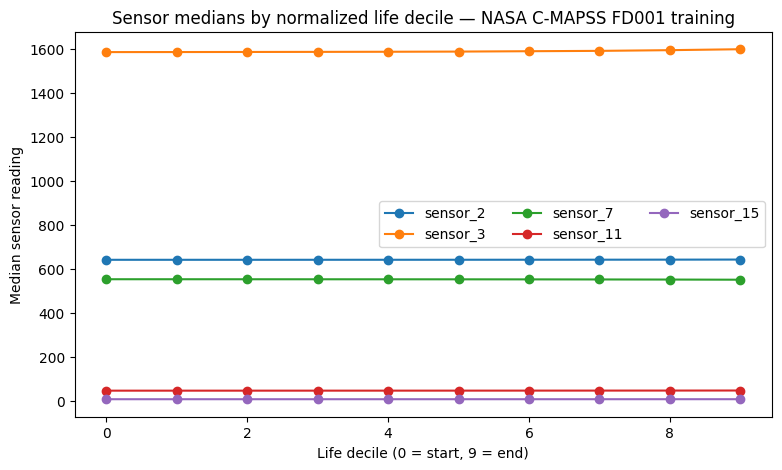

**Finding 3.** Among the plotted sensors, **sensor_3** has the largest absolute change between first and last life-decile medians: **+13.060** sensor units. The plot displays the measured trends; scale and dataset source matter.

In [4]:
trend_data = analysis_frame.copy()
last_cycle = trend_data.groupby("machine_id").cycle.transform("max")
trend_data["life_fraction"] = np.where(
    last_cycle > 1, (trend_data.cycle - 1) / (last_cycle - 1), 0.0
)
trend_data["life_decile"] = pd.cut(
    trend_data.life_fraction,
    bins=np.linspace(0, 1, 11),
    include_lowest=True,
    labels=False,
)
sensor_columns = [column for column in trend_data if column.startswith("sensor_")]
selected_sensors = [
    column
    for column in ("sensor_2", "sensor_3", "sensor_7", "sensor_11", "sensor_15")
    if column in sensor_columns
]
if len(selected_sensors) < 2:
    selected_sensors = sensor_columns[: min(5, len(sensor_columns))]
sensor_trends = trend_data.groupby("life_decile", observed=True)[
    selected_sensors
].median()
fig, ax = plt.subplots(figsize=(9, 5))
for sensor in selected_sensors:
    ax.plot(sensor_trends.index, sensor_trends[sensor], marker="o", label=sensor)
ax.set(
    title=f"Sensor medians by normalized life decile — {analysis_label}",
    xlabel="Life decile (0 = start, 9 = end)",
    ylabel="Median sensor reading",
)
ax.legend(ncol=3)
plt.show()
trend_changes = (sensor_trends.iloc[-1] - sensor_trends.iloc[0]).sort_values(
    key=abs, ascending=False
)
largest_sensor = str(trend_changes.index[0])
largest_change = float(trend_changes.iloc[0])
display(
    Markdown(
        f"**Finding 3.** Among the plotted sensors, **{largest_sensor}** has the "
        f"largest absolute change between first and last life-decile medians: "
        f"**{largest_change:+.3f}** sensor units. The plot displays the measured "
        "trends; scale and dataset source matter."
    )
)

## 4. Sensor dependence

The correlation matrix is descriptive and is not evidence that correlated sensors are independent, causal, or useful predictors.

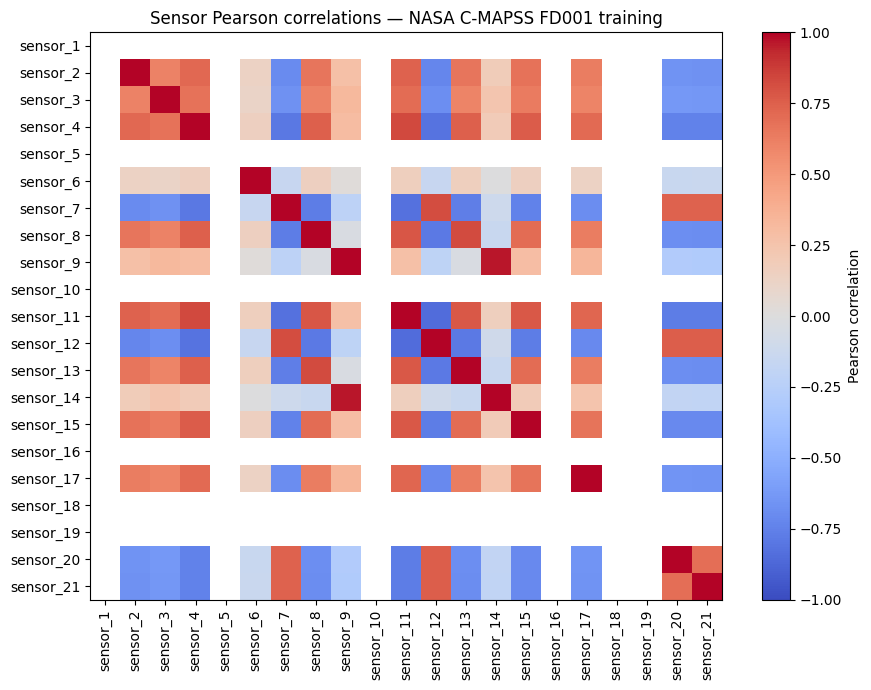

**Finding 4.** The strongest absolute off-diagonal Pearson correlation is between **sensor_9** and **sensor_14** (r = 0.963). This summarizes linear association over the included cycles.

In [5]:
correlation = analysis_frame[sensor_columns].corr(method="pearson")
upper_triangle = correlation.where(
    np.triu(np.ones(correlation.shape), k=1).astype(bool)
)
top_pair = upper_triangle.abs().stack().idxmax()
top_correlation = float(correlation.loc[top_pair[0], top_pair[1]])
fig, ax = plt.subplots(figsize=(9, 7))
image = ax.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(sensor_columns)), sensor_columns, rotation=90)
ax.set_yticks(range(len(sensor_columns)), sensor_columns)
ax.set_title(f"Sensor Pearson correlations — {analysis_label}")
fig.colorbar(image, ax=ax, label="Pearson correlation")
plt.tight_layout()
plt.show()
display(
    Markdown(
        f"**Finding 4.** The strongest absolute off-diagonal Pearson correlation is "
        f"between **{top_pair[0]}** and **{top_pair[1]}** (r = "
        f"{top_correlation:.3f}). This summarizes linear association over the "
        "included cycles."
    )
)

## 5. Operating-setting variation

When NASA FD001 and FD002 are available, compare their observed first operating setting. Otherwise, compare the synthetic generator's explicitly simulated operating modes.

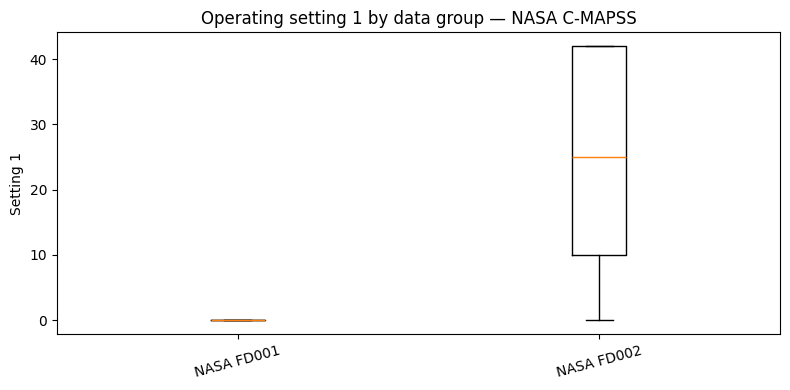

**Finding 5.** The group with the largest observed setting-1 standard deviation is **NASA FD002** (SD = 14.7474); the smallest is **NASA FD001** (SD = 0.0022). This is a descriptive comparison, not a causal effect.

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
if fd001 is not None and fd002 is not None:
    setting_groups = [fd001.setting_1, fd002.setting_1]
    setting_labels = ["NASA FD001", "NASA FD002"]
    setting_source = "NASA C-MAPSS"
else:
    modes = sorted(synthetic.operating_condition.unique())
    setting_groups = [
        synthetic.loc[synthetic.operating_condition.eq(mode), "setting_1"]
        for mode in modes
    ]
    setting_labels = [f"Simulated mode {mode}" for mode in modes]
    setting_source = "synthetic simulation"
ax.boxplot(setting_groups, tick_labels=setting_labels, showfliers=False)
ax.set(
    title=f"Operating setting 1 by data group — {setting_source}",
    ylabel="Setting 1",
)
ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()
setting_spreads = [float(values.std()) for values in setting_groups]
spread_order = np.argsort(setting_spreads)[::-1]
display(
    Markdown(
        f"**Finding 5.** The group with the largest observed setting-1 standard "
        f"deviation is **{setting_labels[int(spread_order[0])]}** (SD = "
        f"{setting_spreads[int(spread_order[0])]:.4f}); the smallest is "
        f"**{setting_labels[int(spread_order[-1])]}** (SD = "
        f"{setting_spreads[int(spread_order[-1])]:.4f}). This is a descriptive "
        "comparison, not a causal effect."
    )
)

## 6. Synthetic maintenance and machine-type variation

The synthetic generator contains one terminal failure per machine and optional maintenance indicators. Rates are normalized by observed machine-cycle exposure. These are simulation outcomes, not estimates of real-fleet behavior.

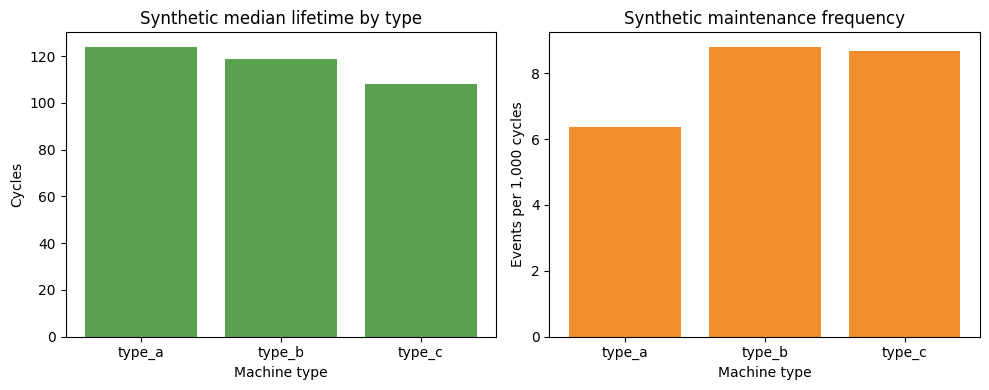

**Finding 6.** In this seed-42 simulation, **type_b** has the highest maintenance-event rate (8.802 per 1,000 cycles). The chart also shows simulated lifetime differences by type.

In [7]:
synthetic_lifetimes = machine_lifetimes(synthetic)
synthetic_by_type = (
    synthetic_lifetimes.groupby("machine_type")
    .agg(
        machines=("machine_id", "count"),
        median_lifetime_cycles=("exposure_cycles", "median"),
        maintenance_events=("maintenance_events", "sum"),
        failures=("failure_events", "sum"),
    )
    .reset_index()
)
synthetic_maintenance = calculate_maintenance_frequency(
    synthetic, group_by=("machine_type",)
)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].bar(
    synthetic_by_type.machine_type,
    synthetic_by_type.median_lifetime_cycles,
    color="#59A14F",
)
axes[0].set(
    title="Synthetic median lifetime by type",
    xlabel="Machine type",
    ylabel="Cycles",
)
axes[1].bar(
    synthetic_maintenance.machine_type,
    synthetic_maintenance.events_per_1000_cycles,
    color="#F28E2B",
)
axes[1].set(
    title="Synthetic maintenance frequency",
    xlabel="Machine type",
    ylabel="Events per 1,000 cycles",
)
plt.tight_layout()
plt.show()
highest_maintenance = synthetic_maintenance.sort_values(
    "events_per_1000_cycles", ascending=False
).iloc[0]
display(
    Markdown(
        f"**Finding 6.** In this seed-42 simulation, "
        f"**{highest_maintenance.machine_type}** has the highest maintenance-event "
        f"rate ({highest_maintenance.events_per_1000_cycles:.3f} per 1,000 cycles). "
        "The chart also shows simulated lifetime differences by type."
    )
)

## 7. Missing sensor observations

Missingness is reported as a data-quality property; this notebook does not impute values.

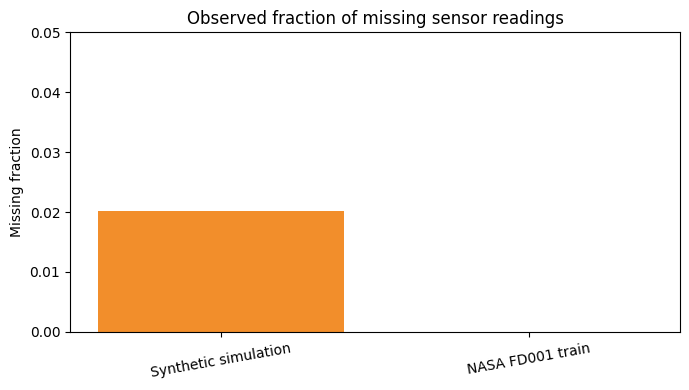

**Finding 7.** Observed sensor missing fractions are Synthetic simulation: **2.018%**; NASA FD001 train: **0.000%**. These rates are measured from loaded rows; no missing values were filled.

In [8]:
missing_groups = {
    "Synthetic simulation": float(
        synthetic.filter(regex=r"^sensor_").isna().to_numpy().mean()
    )
}
if fd001 is not None:
    nasa_sensors = fd001.filter(regex=r"^sensor_").columns
    missing_groups["NASA FD001 train"] = float(
        fd001[nasa_sensors].isna().to_numpy().mean()
    )
missing_names = list(missing_groups)
missing_values = list(missing_groups.values())
fig, ax = plt.subplots(figsize=(7, 4))
colors = ["#F28E2B", "#2878B5"][: len(missing_names)]
ax.bar(missing_names, missing_values, color=colors)
ax.set(
    title="Observed fraction of missing sensor readings",
    ylabel="Missing fraction",
    ylim=(0, max(0.05, max(missing_values) * 1.2)),
)
ax.tick_params(axis="x", rotation=10)
plt.tight_layout()
plt.show()
missing_finding = "; ".join(
    f"{name}: **{value:.3%}**" for name, value in missing_groups.items()
)
display(
    Markdown(
        f"**Finding 7.** Observed sensor missing fractions are {missing_finding}. "
        "These rates are measured from loaded rows; no missing values were filled."
    )
)

## Metric availability and interpretation

MTBF requires recurrent failures on the same machine; downtime requires measured downtime duration. C-MAPSS and this synthetic generator provide a single terminal failure and no downtime-hours field, so those metrics are reported unavailable rather than approximated. Failure rates use observed cycle exposure; censored trajectories contribute exposure but not an unobserved terminal failure.

In [9]:
metric_summary = pd.DataFrame(
    [
        {
            "dataset": analysis_label,
            "failure_rate_per_1000_cycles": calculate_failure_rates(analysis_frame)
            .iloc[0]
            .failure_rate_per_1000_cycles,
            "mtbf": calculate_mtbf(analysis_frame)["reason"],
            "downtime": calculate_downtime(analysis_frame)["reason"],
        },
        {
            "dataset": "synthetic simulation",
            "failure_rate_per_1000_cycles": calculate_failure_rates(synthetic)
            .iloc[0]
            .failure_rate_per_1000_cycles,
            "mtbf": calculate_mtbf(synthetic)["reason"],
            "downtime": calculate_downtime(synthetic)["reason"],
        },
    ]
)
display(metric_summary)
print(
    "Findings above are computed from loaded data; no benchmark or causal "
    "claim is made."
)

,dataset,failure_rate_per_1000_cycles,mtbf,downtime
0,NASA C-MAPSS FD001 training,4.847075,No machine has two or more observed failure ev...,Dataset does not contain measured downtime_hours.
1,synthetic simulation,8.378718,No machine has two or more observed failure ev...,Dataset does not contain measured downtime_hours.


Findings above are computed from loaded data; no benchmark or causal claim is made.
